In [1]:

import pandas as pd
import numpy as np
from scipy.io import arff

file_path = "/kaggle/input/datasets/h7alasaleh/autism-screening-adult/Autism-Adult-Data.arff"

data, meta = arff.loadarff(file_path)

df = pd.DataFrame(data)

for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isin(["?"]).sum().sort_values(ascending=False))

print("\nTarget distribution:")
print(df["Class/ASD"].value_counts(dropna=False))

Dataset shape: (704, 21)

First 5 rows:


,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,...,gender,ethnicity,jundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,1,1,0,0,1,1,0,0,...,f,White-European,no,no,United States,no,6.0,18 and more,Self,NO
1,1,1,0,1,0,0,0,1,0,1,...,m,Latino,no,yes,Brazil,no,5.0,18 and more,Self,NO
2,1,1,0,1,1,0,1,1,1,1,...,m,Latino,yes,yes,Spain,no,8.0,18 and more,Parent,YES
3,1,1,0,1,0,0,1,1,0,1,...,f,White-European,no,yes,United States,no,6.0,18 and more,Self,NO
4,1,0,0,0,0,0,0,1,0,0,...,f,?,no,no,Egypt,no,2.0,18 and more,?,NO



Column names:
['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender', 'ethnicity', 'jundice', 'austim', 'contry_of_res', 'used_app_before', 'result', 'age_desc', 'relation', 'Class/ASD']

Data types:
A1_Score            object
A2_Score            object
A3_Score            object
A4_Score            object
A5_Score            object
A6_Score            object
A7_Score            object
A8_Score            object
A9_Score            object
A10_Score           object
age                float64
gender              object
ethnicity           object
jundice             object
austim              object
contry_of_res       object
used_app_before     object
result             float64
age_desc            object
relation            object
Class/ASD           object
dtype: object

Missing values:
ethnicity          95
relation           95
A3_Score            0
A2_Score            0
A1_Score            0
A5_Score

In [2]:

df_check = df.replace("?", np.nan).copy()

print("Missing values (including '?'):")
display(
    df_check.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

score_cols = [f"A{i}_Score" for i in range(1, 11)]

print("\nUnique values in screening scores:")
for col in score_cols:
    print(f"{col}: {df_check[col].unique()}")

print("\nUnique values in result:")
print(df_check["result"].value_counts(dropna=False).sort_index())

print("\nUnique values in age_desc:")
print(df_check["age_desc"].value_counts(dropna=False))

categorical_cols = [
    "gender", "ethnicity", "jundice", "austim",
    "contry_of_res", "used_app_before", "relation"
]

print("\nNumber of unique values in categorical columns:")
for col in categorical_cols:
    print(f"{col}: {df_check[col].nunique(dropna=True)}")

print("\nColumns with only one unique value:")
print([
    col for col in df_check.columns
    if df_check[col].nunique(dropna=False) == 1
])

print("\nNumeric summary:")
display(df_check[["age", "result"]].describe())

Missing values (including '?'):


,Missing_Count
ethnicity,95
relation,95
age,2
A2_Score,0
A1_Score,0
A5_Score,0
A4_Score,0
A3_Score,0
A6_Score,0
A9_Score,0



Unique values in screening scores:
A1_Score: ['1' '0']
A2_Score: ['1' '0']
A3_Score: ['1' '0']
A4_Score: ['1' '0']
A5_Score: ['0' '1']
A6_Score: ['0' '1']
A7_Score: ['1' '0']
A8_Score: ['1' '0']
A9_Score: ['0' '1']
A10_Score: ['0' '1']

Unique values in result:
result
0.0      14
1.0      33
2.0      74
3.0     110
4.0     131
5.0      83
6.0      70
7.0      57
8.0      55
9.0      47
10.0     30
Name: count, dtype: int64

Unique values in age_desc:
age_desc
18 and more    704
Name: count, dtype: int64

Number of unique values in categorical columns:
gender: 2
ethnicity: 11
jundice: 2
austim: 2
contry_of_res: 67
used_app_before: 2
relation: 5

Columns with only one unique value:
['age_desc']

Numeric summary:


,age,result
count,702.000000,704.000000
mean,29.698006,4.875000
std,16.507465,2.501493
min,17.000000,0.000000
25%,21.000000,3.000000
50%,27.000000,4.000000
75%,35.000000,7.000000
max,383.000000,10.000000


In [3]:

df_check = df.replace("?", np.nan).copy()

score_cols = [f"A{i}_Score" for i in range(1, 11)]

for col in score_cols:
    df_check[col] = pd.to_numeric(df_check[col], errors="coerce")

print("Ages greater than 100:")
display(
    df_check.loc[df_check["age"] > 100,
                 ["age", "gender", "Class/ASD"]]
)

print("\nAge values below 0:")
display(df_check.loc[df_check["age"] < 0, ["age", "Class/ASD"]])

score_sum = df_check[score_cols].sum(axis=1)

comparison = pd.DataFrame({
    "result": df_check["result"],
    "sum_of_scores": score_sum
})

comparison["match"] = (
    comparison["result"] == comparison["sum_of_scores"]
)

print("\nDoes result equal the sum of the ten scores?")
print(comparison["match"].value_counts(dropna=False))


print("\nExamples of mismatches:")
display(comparison.loc[~comparison["match"]].head(10))

print("\nTarget distribution for each result score:")
display(
    pd.crosstab(
        df_check["result"],
        df_check["Class/ASD"],
        normalize="index"
    ).round(3)
)

Ages greater than 100:


,age,gender,Class/ASD
52,383.0,f,NO



Age values below 0:


,age,Class/ASD



Does result equal the sum of the ten scores?
match
True    704
Name: count, dtype: int64

Examples of mismatches:


,result,sum_of_scores,match



Target distribution for each result score:


Class/ASD,NO,YES
result,,
0.0,1.0,0.0
1.0,1.0,0.0
2.0,1.0,0.0
3.0,1.0,0.0
4.0,1.0,0.0
5.0,1.0,0.0
6.0,1.0,0.0
7.0,0.0,1.0
8.0,0.0,1.0


In [4]:

df_clean = df.copy()
df_clean = df_clean.replace("?", np.nan)

score_cols = [f"A{i}_Score" for i in range(1, 11)]

for col in score_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean["age"] = pd.to_numeric(df_clean["age"], errors="coerce")

df_clean.loc[
    (df_clean["age"] > 100) | (df_clean["age"] < 0),
    "age"
] = np.nan

df_clean = df_clean.drop(
    columns=["result", "age_desc"],
    errors="ignore"
)

target_col = "Class/ASD"

X = df_clean.drop(columns=[target_col]).copy()
y = df_clean[target_col].copy()

y = y.astype(str).str.strip().str.upper()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values per column:")
display(
    X.isna().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
)

print("\nTarget distribution:")
display(y.value_counts().to_frame("Count"))

print("\nTarget distribution (%):")
display(
    (y.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

print("\nData types:")
display(X.dtypes.to_frame("Data_Type"))


Original dataset shape: (704, 21)
Cleaned dataset shape: (704, 19)
Features shape: (704, 18)
Target shape: (704,)

Missing values per column:


,Missing_Count
ethnicity,95
relation,95
age,3
A1_Score,0
A2_Score,0
A3_Score,0
A7_Score,0
A4_Score,0
A5_Score,0
A6_Score,0



Target distribution:


,Count
Class/ASD,
NO,515
YES,189



Target distribution (%):


,Percentage
Class/ASD,
NO,73.15
YES,26.85



Data types:


,Data_Type
A1_Score,int64
A2_Score,int64
A3_Score,int64
A4_Score,int64
A5_Score,int64
A6_Score,int64
A7_Score,int64
A8_Score,int64
A9_Score,int64
A10_Score,int64


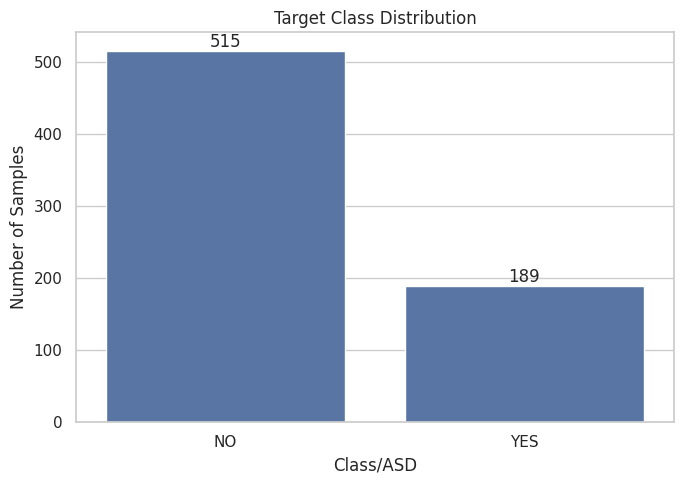

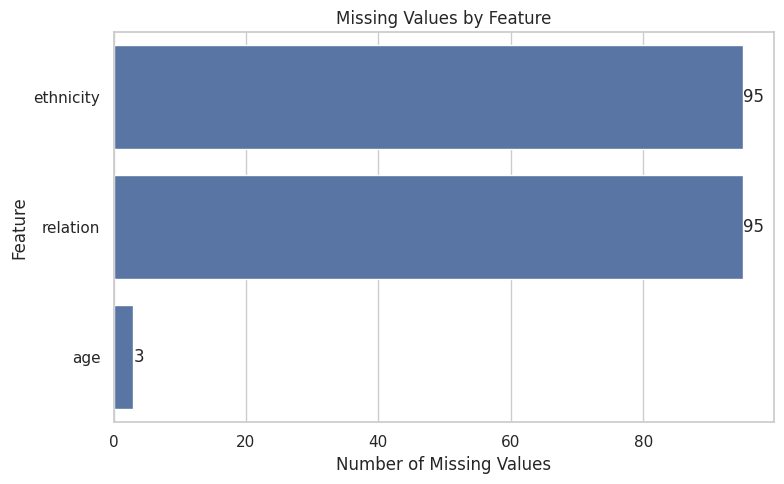

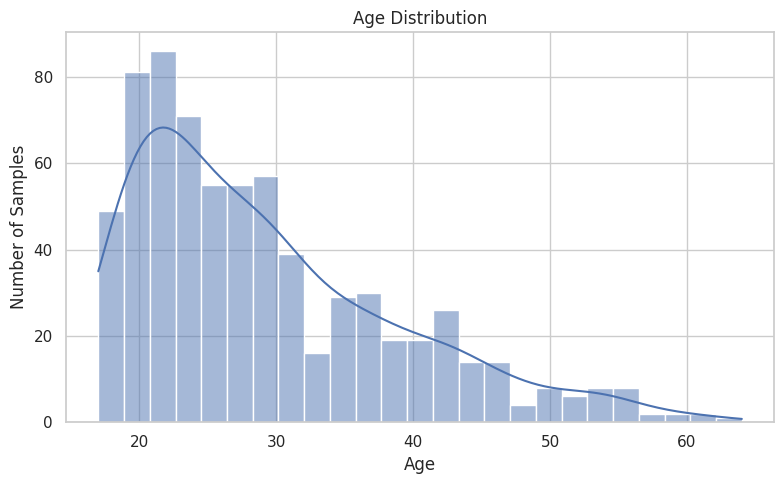

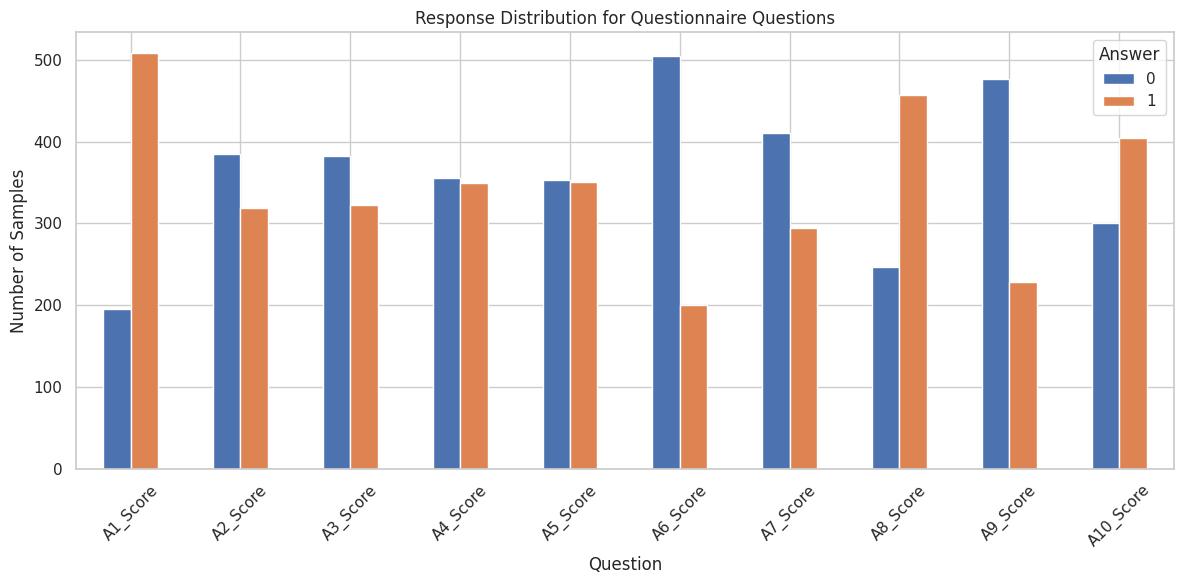

EDA plots saved to: /kaggle/working/project_outputs/eda


In [5]:

import os
import matplotlib.pyplot as plt
import seaborn as sns

output_dir = "/kaggle/working/project_outputs"
eda_dir = os.path.join(output_dir, "eda")
os.makedirs(eda_dir, exist_ok=True)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
ax = sns.countplot(
    data=df_clean,
    x="Class/ASD",
    order=["NO", "YES"]
)
ax.set_title("Target Class Distribution")
ax.set_xlabel("Class/ASD")
ax.set_ylabel("Number of Samples")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(
    os.path.join(eda_dir, "target_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


missing = df_clean.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=missing.values,
    y=missing.index
)
ax.set_title("Missing Values by Feature")
ax.set_xlabel("Number of Missing Values")
ax.set_ylabel("Feature")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(
    os.path.join(eda_dir, "missing_values.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="age",
    bins=25,
    kde=True,
    stat="count"
)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.savefig(
    os.path.join(eda_dir, "age_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


score_cols = [f"A{i}_Score" for i in range(1, 11)]

score_counts = pd.DataFrame({
    "Score": ["0", "1"],
    **{
        col: [
            (df_clean[col] == 0).sum(),
            (df_clean[col] == 1).sum()
        ]
        for col in score_cols
    }
})

score_plot = score_counts.set_index("Score").T

ax = score_plot.plot(
    kind="bar",
    figsize=(12, 6)
)
ax.set_title("Response Distribution for Questionnaire Questions")
ax.set_xlabel("Question")
ax.set_ylabel("Number of Samples")
ax.legend(title="Answer")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    os.path.join(eda_dir, "question_response_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("EDA plots saved to:", eda_dir)


In [6]:

from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training samples: 563
Testing samples: 141

Training target distribution:
Class/ASD
NO     0.732
YES    0.268
Name: proportion, dtype: float64

Testing target distribution:
Class/ASD
NO     0.73
YES    0.27
Name: proportion, dtype: float64


In [7]:

from itertools import product

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

numeric_features = ["age"] + score_cols

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

age_strategies = ["median", "mean"]
ethnicity_strategies = ["most_frequent", "unknown"]
relation_strategies = ["most_frequent", "unknown"]

results = []

for age_strategy, ethnicity_strategy, relation_strategy in product(
    age_strategies,
    ethnicity_strategies,
    relation_strategies
):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=age_strategy))
    ])

    ethnicity_fill = (
        "Unknown"
        if ethnicity_strategy == "unknown"
        else None
    )

    relation_fill = (
        "Unknown"
        if relation_strategy == "unknown"
        else None
    )

    ethnicity_imputer = SimpleImputer(
        strategy=(
            "constant"
            if ethnicity_strategy == "unknown"
            else "most_frequent"
        ),
        fill_value=ethnicity_fill
    )

    relation_imputer = SimpleImputer(
        strategy=(
            "constant"
            if relation_strategy == "unknown"
            else "most_frequent"
        ),
        fill_value=relation_fill
    )

    categorical_pipeline = ColumnTransformer(
        transformers=[
            ("ethnicity", ethnicity_imputer, ["ethnicity"]),
            ("relation", relation_imputer, ["relation"]),
            (
                "other_categories",
                SimpleImputer(strategy="most_frequent"),
                [
                    col for col in categorical_features
                    if col not in ["ethnicity", "relation"]
                ]
            )
        ],
        remainder="drop"
    )

    preprocessing = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            (
                "categorical",
                Pipeline([
                    ("imputer", categorical_pipeline),
                    (
                        "onehot",
                        OneHotEncoder(handle_unknown="ignore")
                    )
                ]),
                categorical_features
            )
        ]
    )

    model_pipeline = Pipeline([
        ("preprocessing", preprocessing),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            )
        )
    ])

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1_macro": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy"
        },
        n_jobs=-1,
        return_train_score=False
    )

    results.append({
        "Age_Imputation": age_strategy,
        "Ethnicity_Imputation": ethnicity_strategy,
        "Relation_Imputation": relation_strategy,
        "Mean_F1_Macro": scores["test_f1_macro"].mean(),
        "Std_F1_Macro": scores["test_f1_macro"].std(),
        "Mean_Balanced_Accuracy":
            scores["test_balanced_accuracy"].mean(),
        "Mean_Accuracy": scores["test_accuracy"].mean()
    })

imputation_results = (
    pd.DataFrame(results)
    .sort_values("Mean_F1_Macro", ascending=False)
    .reset_index(drop=True)
)

display(imputation_results.round(4))

imputation_results.to_csv(
    "/kaggle/working/imputation_comparison.csv",
    index=False
)


,Age_Imputation,Ethnicity_Imputation,Relation_Imputation,Mean_F1_Macro,Std_F1_Macro,Mean_Balanced_Accuracy,Mean_Accuracy
0,median,most_frequent,most_frequent,0.9462,0.0221,0.9344,0.9591
1,mean,most_frequent,most_frequent,0.9462,0.0221,0.9344,0.9591
2,mean,unknown,unknown,0.9462,0.0209,0.9343,0.9591
3,median,unknown,unknown,0.9462,0.0209,0.9343,0.9591
4,median,unknown,most_frequent,0.9439,0.0231,0.9330,0.9573
5,mean,unknown,most_frequent,0.9415,0.0248,0.9297,0.9556
6,mean,most_frequent,unknown,0.9387,0.0235,0.9243,0.9538
7,median,most_frequent,unknown,0.9361,0.0265,0.9209,0.9520


In [8]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

numeric_features = ["age"] + score_cols

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

def build_preprocessor(scaling_method="standard"):

    if scaling_method == "standard":
        scaler = StandardScaler()
    elif scaling_method == "minmax":
        scaler = MinMaxScaler()
    else:
        raise ValueError("Use 'standard' or 'minmax'.")

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler)
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ) if "sparse_output" in
        OneHotEncoder.__init__.__code__.co_varnames
        else OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Numeric features: ['age', 'A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score']
Categorical features: ['gender', 'ethnicity', 'jundice', 'austim', 'contry_of_res', 'used_app_before', 'relation']
Number of numeric features: 11
Number of categorical features: 7


In [9]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "SVM": SVC(
        probability=True,
        random_state=42,
        class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

scaling_methods = ["standard", "minmax"]
model_results = []

for scaling in scaling_methods:
    for model_name, model in models.items():

        pipeline = Pipeline([
            ("preprocessing", build_preprocessor(scaling)),
            ("classifier", model)
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "f1_macro": "f1_macro",
                "balanced_accuracy": "balanced_accuracy",
                "roc_auc": "roc_auc"
            },
            n_jobs=-1,
            return_train_score=False
        )

        model_results.append({
            "Scaling": scaling,
            "Model": model_name,
            "Mean_Accuracy": scores["test_accuracy"].mean(),
            "Mean_F1_Macro": scores["test_f1_macro"].mean(),
            "Mean_Balanced_Accuracy":
                scores["test_balanced_accuracy"].mean(),
            "Mean_ROC_AUC": scores["test_roc_auc"].mean(),
            "Std_F1_Macro": scores["test_f1_macro"].std()
        })

model_comparison = (
    pd.DataFrame(model_results)
    .sort_values("Mean_F1_Macro", ascending=False)
    .reset_index(drop=True)
)

display(model_comparison.round(4))

os.makedirs("/kaggle/working/project_outputs", exist_ok=True)

model_comparison.to_csv(
    "/kaggle/working/project_outputs/model_scaling_comparison.csv",
    index=False
)


,Scaling,Model,Mean_Accuracy,Mean_F1_Macro,Mean_Balanced_Accuracy,Mean_ROC_AUC,Std_F1_Macro
0,minmax,AdaBoost,0.9982,0.9977,0.9967,1.0000,0.0046
1,standard,AdaBoost,0.9982,0.9977,0.9967,1.0000,0.0046
2,standard,SVM,0.9752,0.9686,0.9725,0.9978,0.0148
3,minmax,SVM,0.9698,0.9624,0.9731,0.9966,0.0088
4,standard,KNN,0.9538,0.9421,0.9475,0.9917,0.0155
5,standard,Random Forest,0.9538,0.9388,0.9244,0.9926,0.0208
6,minmax,Random Forest,0.9538,0.9388,0.9244,0.9926,0.0208
7,minmax,KNN,0.9449,0.9314,0.9413,0.9794,0.0257
8,minmax,Decision Tree,0.8845,0.8554,0.8604,0.8604,0.0221
9,standard,Decision Tree,0.8845,0.8554,0.8604,0.8604,0.0221


In [10]:

from sklearn.ensemble import VotingClassifier

voting_estimators = [
    (
        "svm",
        Pipeline([
            ("preprocessing", build_preprocessor("standard")),
            ("classifier", SVC(
                probability=True,
                random_state=42,
                class_weight="balanced"
            ))
        ])
    ),
    (
        "knn",
        Pipeline([
            ("preprocessing", build_preprocessor("standard")),
            ("classifier", KNeighborsClassifier(n_neighbors=5))
        ])
    ),
    (
        "random_forest",
        Pipeline([
            ("preprocessing", build_preprocessor("standard")),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            ))
        ])
    ),
    (
        "naive_bayes",
        Pipeline([
            ("preprocessing", build_preprocessor("standard")),
            ("classifier", GaussianNB())
        ])
    ),
    (
        "decision_tree",
        Pipeline([
            ("preprocessing", build_preprocessor("standard")),
            ("classifier", DecisionTreeClassifier(
                random_state=42,
                class_weight="balanced"
            ))
        ])
    ),
    (
        "adaboost",
        Pipeline([
            ("preprocessing", build_preprocessor("standard")),
            ("classifier", AdaBoostClassifier(random_state=42))
        ])
    )
]

soft_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="soft",
    n_jobs=-1
)

# SVM, KNN, Random Forest, Naive Bayes,
#          Decision Tree, AdaBoost
weighted_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="soft",
    weights=[5, 4, 3, 1, 2, 6],
    n_jobs=-1
)

voting_models = {
    "Soft Voting": soft_voting,
    "Weighted Voting": weighted_voting
}

voting_results = []

for model_name, model in voting_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=1,
        return_train_score=False
    )

    voting_results.append({
        "Model": model_name,
        "Mean_Accuracy": scores["test_accuracy"].mean(),
        "Mean_F1_Macro": scores["test_f1_macro"].mean(),
        "Mean_Balanced_Accuracy":
            scores["test_balanced_accuracy"].mean(),
        "Mean_ROC_AUC": scores["test_roc_auc"].mean(),
        "Std_F1_Macro": scores["test_f1_macro"].std()
    })

voting_comparison = (
    pd.DataFrame(voting_results)
    .sort_values("Mean_F1_Macro", ascending=False)
    .reset_index(drop=True)
)

display(voting_comparison.round(4))

voting_comparison.to_csv(
    "/kaggle/working/project_outputs/voting_comparison.csv",
    index=False
)


,Model,Mean_Accuracy,Mean_F1_Macro,Mean_Balanced_Accuracy,Mean_ROC_AUC,Std_F1_Macro
0,Weighted Voting,0.9716,0.9640,0.9660,0.9960,0.0083
1,Soft Voting,0.9414,0.9278,0.9411,0.9905,0.0180


In [11]:

output_dir = "/kaggle/working/project_outputs"
os.makedirs(output_dir, exist_ok=True)

voting_comparison.to_csv(
    os.path.join(output_dir, "voting_comparison.csv"),
    index=False
)

print("Voting comparison results saved successfully.")
display(voting_comparison.round(4))

print(
    "Saved file:",
    os.path.join(output_dir, "voting_comparison.csv")
)


Voting comparison results saved successfully.


,Model,Mean_Accuracy,Mean_F1_Macro,Mean_Balanced_Accuracy,Mean_ROC_AUC,Std_F1_Macro
0,Weighted Voting,0.9716,0.9640,0.9660,0.9960,0.0083
1,Soft Voting,0.9414,0.9278,0.9411,0.9905,0.0180


Saved file: /kaggle/working/project_outputs/voting_comparison.csv


Evaluating: SVM
Evaluating: KNN
Evaluating: Random Forest
Evaluating: Gaussian Naive Bayes
Evaluating: Decision Tree
Evaluating: AdaBoost
Evaluating: Soft Voting
Evaluating: Weighted Voting


,Model,TN,FP,FN,TP,Accuracy_CM,Accuracy_Sklearn,F1_Score_YES,F1_Macro,Sensitivity_Recall,Specificity,Precision_YES,FPR,FDR,FNR,Balanced_Accuracy,ROC_AUC
0,AdaBoost,103,0,0,38,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000
1,Weighted Voting,102,1,2,36,0.9787,0.9787,0.9600,0.9728,0.9474,0.9903,0.9730,0.0097,0.0270,0.0526,0.9688,0.9969
2,SVM,102,1,3,35,0.9716,0.9716,0.9459,0.9634,0.9211,0.9903,0.9722,0.0097,0.0278,0.0789,0.9557,0.9985
3,KNN,99,4,1,37,0.9645,0.9645,0.9367,0.9560,0.9737,0.9612,0.9024,0.0388,0.0976,0.0263,0.9674,0.9950
4,Soft Voting,97,6,1,37,0.9504,0.9504,0.9136,0.9394,0.9737,0.9417,0.8605,0.0583,0.1395,0.0263,0.9577,0.9936
5,Random Forest,103,0,10,28,0.9291,0.9291,0.8485,0.9011,0.7368,1.0000,1.0000,0.0000,0.0000,0.2632,0.8684,0.9922
6,Decision Tree,93,10,11,27,0.8511,0.8511,0.7200,0.8093,0.7105,0.9029,0.7297,0.0971,0.2703,0.2895,0.8067,0.8067
7,Gaussian Naive Bayes,8,95,2,36,0.3121,0.3121,0.4260,0.2838,0.9474,0.0777,0.2748,0.9223,0.7252,0.0526,0.5125,0.5125



Saved metrics to: /kaggle/working/project_outputs/test_metrics_summary.csv
Saved confusion matrices to: /kaggle/working/project_outputs/confusion_matrices
Saved classification reports to: /kaggle/working/project_outputs/classification_reports


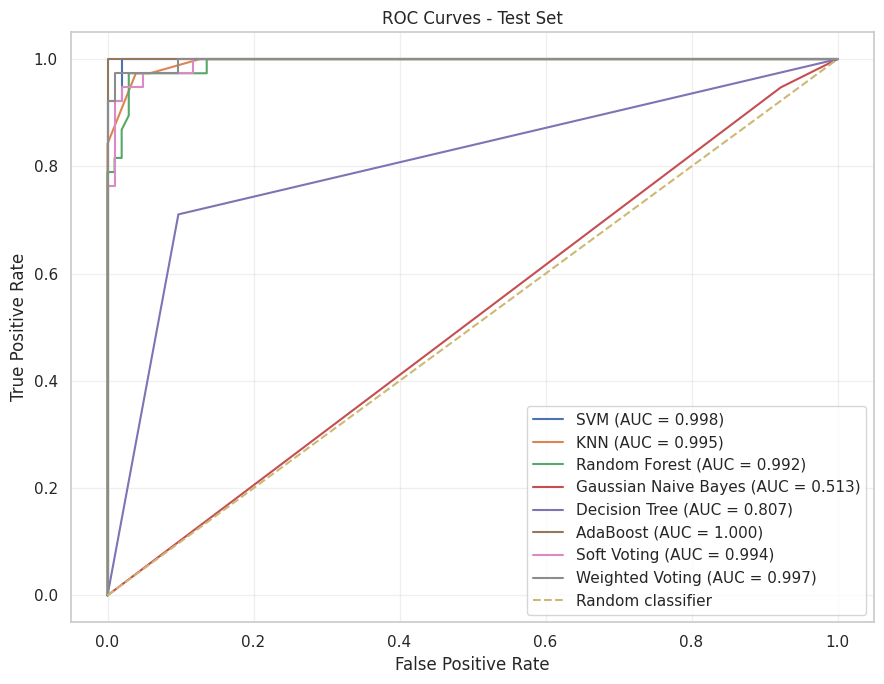

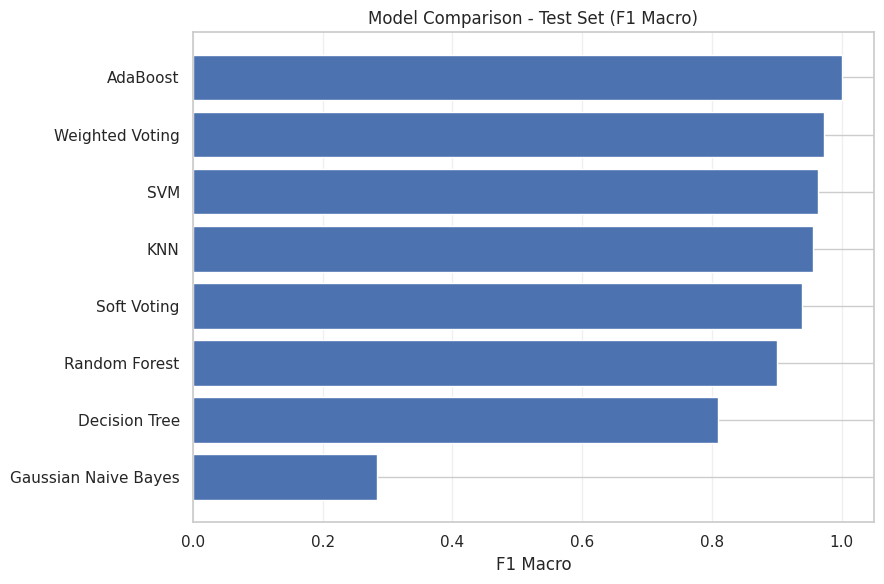


Final test evaluation completed.


In [12]:
from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    balanced_accuracy_score
)

# --------------------------------------------------
# 1. Create output folders
# --------------------------------------------------
output_dir = "/kaggle/working/project_outputs"
cm_dir = os.path.join(output_dir, "confusion_matrices")
report_dir = os.path.join(output_dir, "classification_reports")

os.makedirs(cm_dir, exist_ok=True)
os.makedirs(report_dir, exist_ok=True)

# --------------------------------------------------
# 2. Define the six individual models
#    StandardScaler is used for consistent preprocessing.
# --------------------------------------------------
individual_models = {
    "SVM": Pipeline([
        ("preprocessing", build_preprocessor("standard")),
        ("classifier", SVC(
            probability=True,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessing", build_preprocessor("standard")),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Random Forest": Pipeline([
        ("preprocessing", build_preprocessor("standard")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("preprocessing", build_preprocessor("standard")),
        ("classifier", GaussianNB())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessing", build_preprocessor("standard")),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "AdaBoost": Pipeline([
        ("preprocessing", build_preprocessor("standard")),
        ("classifier", AdaBoostClassifier(random_state=42))
    ])
}

# --------------------------------------------------
# 3. Define Soft Voting and Weighted Voting
#    Keep the previously selected weights unchanged.
#    Order: SVM, KNN, Random Forest, GaussianNB,
#           Decision Tree, AdaBoost
# --------------------------------------------------
soft_voting_model = VotingClassifier(
    estimators=[
        (name.lower().replace(" ", "_"), clone(model))
        for name, model in individual_models.items()
    ],
    voting="soft",
    n_jobs=-1
)

weighted_voting_model = VotingClassifier(
    estimators=[
        (name.lower().replace(" ", "_"), clone(model))
        for name, model in individual_models.items()
    ],
    voting="soft",
    weights=[5, 4, 3, 1, 2, 6],
    n_jobs=-1
)

models = {
    **individual_models,
    "Soft Voting": soft_voting_model,
    "Weighted Voting": weighted_voting_model
}

# --------------------------------------------------
# 4. Prepare target labels
# --------------------------------------------------
y_train_eval = pd.Series(y_train).astype(str).str.strip().str.upper()
y_test_eval = pd.Series(y_test).astype(str).str.strip().str.upper()

positive_label = "YES"
negative_label = "NO"

# Fixed order: TN, FP, FN, TP
labels_order = [negative_label, positive_label]

results = []
roc_data = {}

# --------------------------------------------------
# 5. Fit each model on training data and evaluate
#    only once on the test set
# --------------------------------------------------
for model_name, model in models.items():

    print(f"Evaluating: {model_name}")

    # Train using training data only
    model.fit(X_train, y_train_eval)

    # Predict test labels
    y_pred = model.predict(X_test)
    y_pred = pd.Series(y_pred).astype(str).str.upper().to_numpy()

    # Get probabilities for the YES class
    if not hasattr(model, "predict_proba"):
        raise ValueError(f"{model_name} does not support predict_proba.")

    class_labels = [str(c).upper() for c in model.classes_]
    positive_index = class_labels.index(positive_label)
    y_prob = model.predict_proba(X_test)[:, positive_index]

    # Confusion matrix: [[TN, FP], [FN, TP]]
    cm = confusion_matrix(
        y_test_eval,
        y_pred,
        labels=labels_order
    )
    tn, fp, fn, tp = cm.ravel()

    # Metrics calculated from the confusion matrix
    total = tn + fp + fn + tp

    accuracy_cm = (tp + tn) / total if total else 0
    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    fpr = fp / (fp + tn) if (fp + tn) else 0
    fdr = fp / (fp + tp) if (fp + tp) else 0
    fnr = fn / (fn + tp) if (fn + tp) else 0
    precision_yes = tp / (tp + fp) if (tp + fp) else 0
    f1_yes = (
        2 * precision_yes * sensitivity / (precision_yes + sensitivity)
        if (precision_yes + sensitivity) else 0
    )

    # Other standard metrics
    accuracy_sklearn = accuracy_score(y_test_eval, y_pred)
    f1_macro = f1_score(
        y_test_eval, y_pred,
        labels=labels_order,
        average="macro",
        zero_division=0
    )
    balanced_acc = balanced_accuracy_score(y_test_eval, y_pred)
    auc = roc_auc_score(
        (y_test_eval == positive_label).astype(int),
        y_prob
    )

    results.append({
        "Model": model_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy_CM": accuracy_cm,
        "Accuracy_Sklearn": accuracy_sklearn,
        "F1_Score_YES": f1_yes,
        "F1_Macro": f1_macro,
        "Sensitivity_Recall": sensitivity,
        "Specificity": specificity,
        "Precision_YES": precision_yes,
        "FPR": fpr,
        "FDR": fdr,
        "FNR": fnr,
        "Balanced_Accuracy": balanced_acc,
        "ROC_AUC": auc
    })

    # Save classification report
    report = classification_report(
        y_test_eval,
        y_pred,
        labels=labels_order,
        target_names=["NO", "YES"],
        zero_division=0,
        digits=4
    )

    safe_name = model_name.lower().replace(" ", "_")
    with open(
        os.path.join(report_dir, f"classification_report_{safe_name}.txt"),
        "w",
        encoding="utf-8"
    ) as f:
        f.write(f"Model: {model_name}\n\n")
        f.write(report)
        f.write("\n\nConfusion Matrix:\n")
        f.write(str(cm))

    # Save confusion matrix plot
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"Confusion Matrix - {model_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["NO", "YES"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["NO", "YES"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(
        os.path.join(cm_dir, f"confusion_matrix_{safe_name}.png"),
        dpi=150,
        bbox_inches="tight"
    )
    plt.close(fig)

    # Store ROC coordinates for the combined ROC plot
    fpr_points, tpr_points, _ = roc_curve(
        (y_test_eval == positive_label).astype(int),
        y_prob
    )
    roc_data[model_name] = {
        "fpr": fpr_points,
        "tpr": tpr_points,
        "auc": auc
    }

# --------------------------------------------------
# 6. Save and display the final metrics table
# --------------------------------------------------
test_results = pd.DataFrame(results).sort_values(
    "F1_Macro", ascending=False
).reset_index(drop=True)

test_results.to_csv(
    os.path.join(output_dir, "test_metrics_summary.csv"),
    index=False
)

display(test_results.round(4))

print("\nSaved metrics to:", os.path.join(output_dir, "test_metrics_summary.csv"))
print("Saved confusion matrices to:", cm_dir)
print("Saved classification reports to:", report_dir)

# --------------------------------------------------
# 7. Plot ROC curves for all eight models
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))

for model_name, values in roc_data.items():
    ax.plot(
        values["fpr"],
        values["tpr"],
        label=f"{model_name} (AUC = {values['auc']:.3f})"
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Test Set")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(
    os.path.join(output_dir, "roc_curves_test_set.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 8. Plot model comparison by F1 Macro
# --------------------------------------------------
plot_df = test_results.sort_values("F1_Macro", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df["Model"], plot_df["F1_Macro"])
ax.set_xlabel("F1 Macro")
ax.set_title("Model Comparison - Test Set (F1 Macro)")
ax.set_xlim(0, 1.05)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(
    os.path.join(output_dir, "test_f1_macro_comparison.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("\nFinal test evaluation completed.")


,Model,TN,FP,FN,TP,Accuracy_CM,Accuracy_Sklearn,F1_Score_YES,F1_Macro,Sensitivity_Recall,Specificity,Precision_YES,FPR,FDR,FNR,Balanced_Accuracy,ROC_AUC
0,AdaBoost,103,0,0,38,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000
1,Weighted Voting,102,1,2,36,0.9787,0.9787,0.9600,0.9728,0.9474,0.9903,0.9730,0.0097,0.0270,0.0526,0.9688,0.9969
2,SVM,102,1,3,35,0.9716,0.9716,0.9459,0.9634,0.9211,0.9903,0.9722,0.0097,0.0278,0.0789,0.9557,0.9985
3,KNN,99,4,1,37,0.9645,0.9645,0.9367,0.9560,0.9737,0.9612,0.9024,0.0388,0.0976,0.0263,0.9674,0.9950
4,Soft Voting,97,6,1,37,0.9504,0.9504,0.9136,0.9394,0.9737,0.9417,0.8605,0.0583,0.1395,0.0263,0.9577,0.9936
5,Random Forest,103,0,10,28,0.9291,0.9291,0.8485,0.9011,0.7368,1.0000,1.0000,0.0000,0.0000,0.2632,0.8684,0.9922
6,Decision Tree,93,10,11,27,0.8511,0.8511,0.7200,0.8093,0.7105,0.9029,0.7297,0.0971,0.2703,0.2895,0.8067,0.8067
7,Gaussian Naive Bayes,8,95,2,36,0.3121,0.3121,0.4260,0.2838,0.9474,0.0777,0.2748,0.9223,0.7252,0.0526,0.5125,0.5125


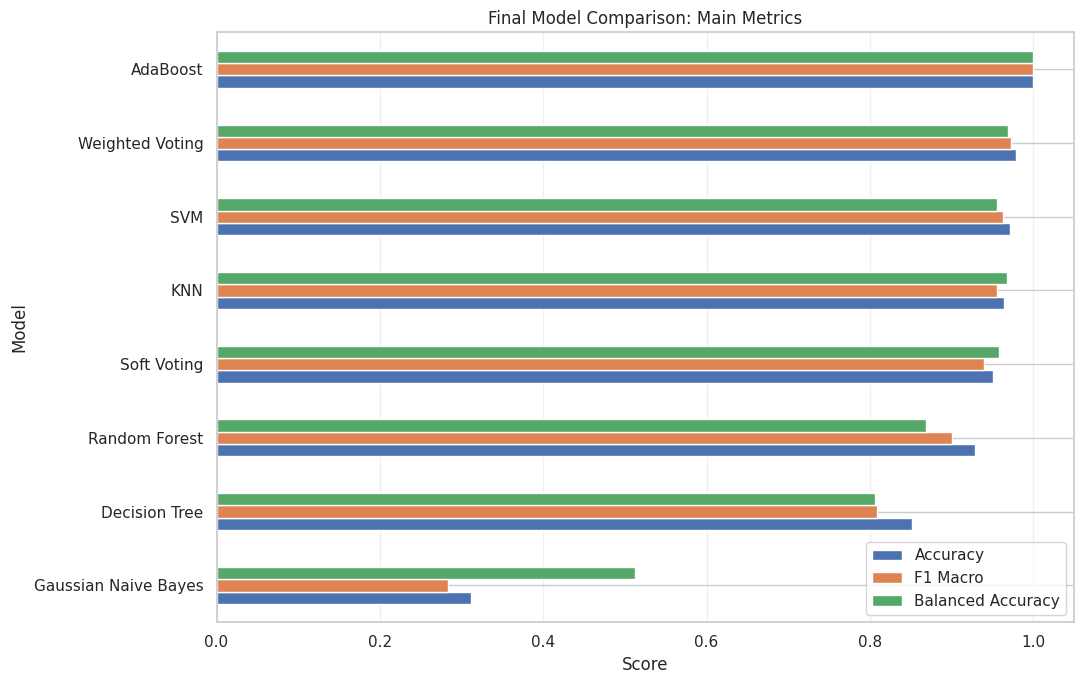

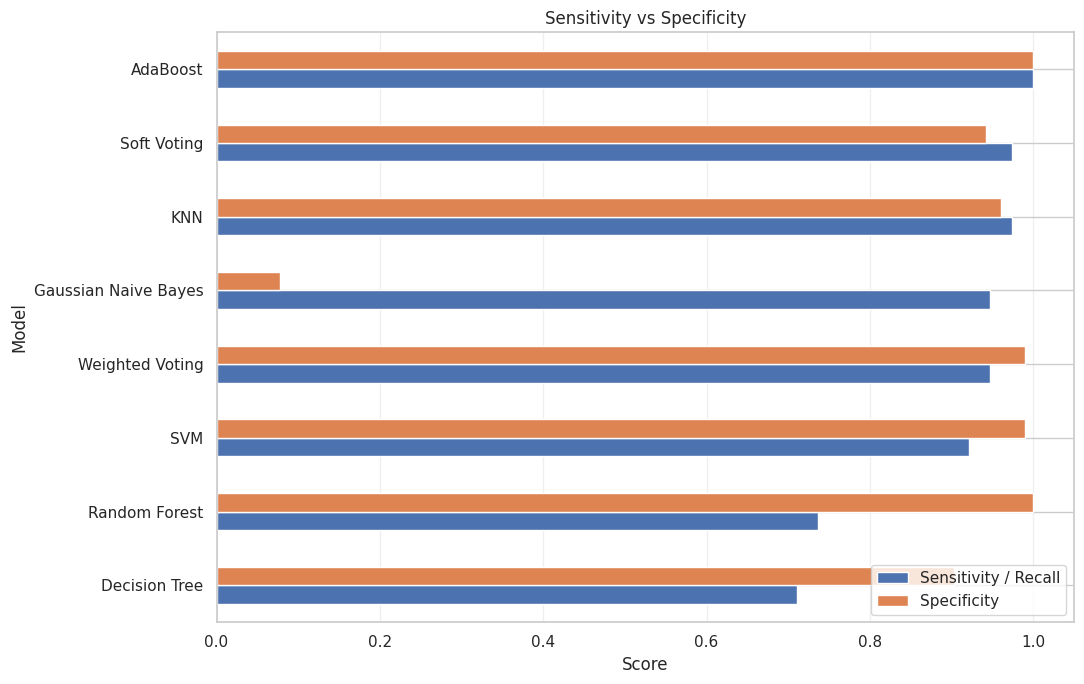

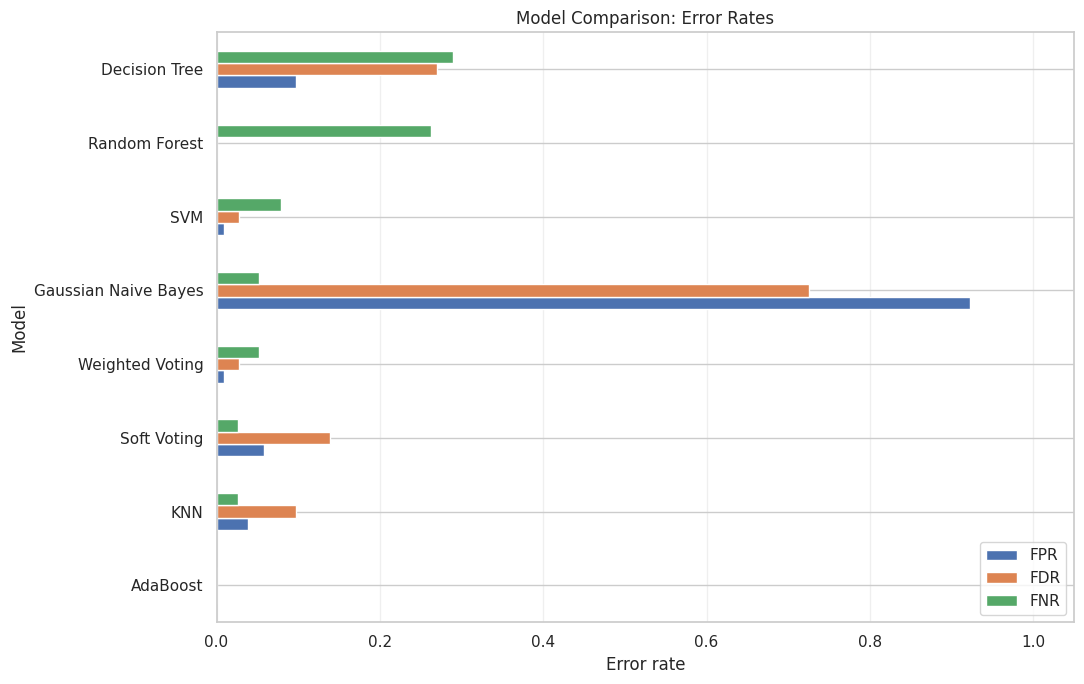

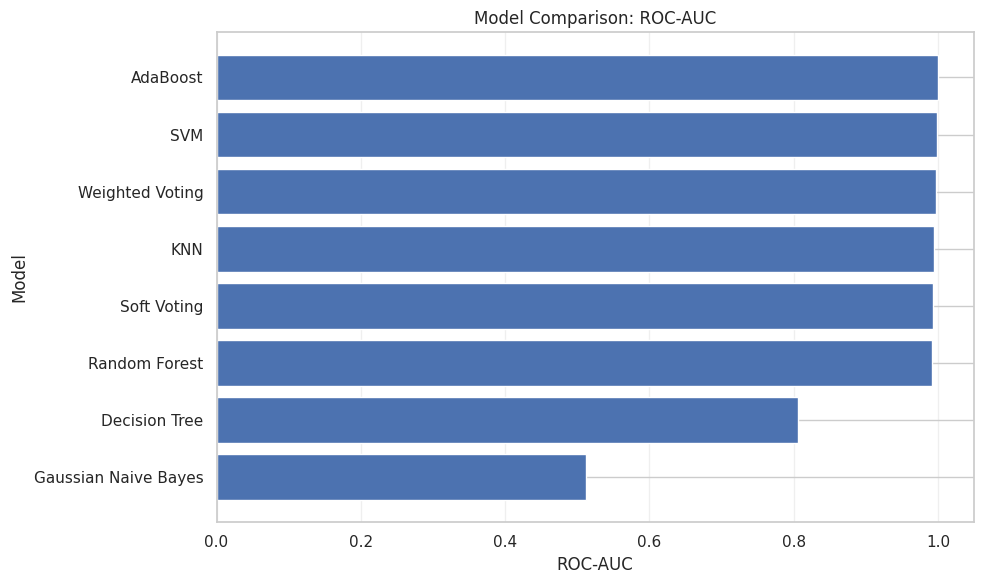


Final ranking:


,Model,Accuracy_Sklearn,F1_Macro,Balanced_Accuracy,Sensitivity_Recall,Specificity,ROC_AUC
0,AdaBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,Weighted Voting,0.9787,0.9728,0.9688,0.9474,0.9903,0.9969
2,SVM,0.9716,0.9634,0.9557,0.9211,0.9903,0.9985
3,KNN,0.9645,0.9560,0.9674,0.9737,0.9612,0.9950
4,Soft Voting,0.9504,0.9394,0.9577,0.9737,0.9417,0.9936
5,Random Forest,0.9291,0.9011,0.8684,0.7368,1.0000,0.9922
6,Decision Tree,0.8511,0.8093,0.8067,0.7105,0.9029,0.8067
7,Gaussian Naive Bayes,0.3121,0.2838,0.5125,0.9474,0.0777,0.5125



Comparison completed.
Saved files:
- /kaggle/working/project_outputs/final_model_comparison.csv
- /kaggle/working/project_outputs/final_model_ranking.csv
- /kaggle/working/project_outputs/comparison_main_metrics.png
- /kaggle/working/project_outputs/comparison_sensitivity_specificity.png
- /kaggle/working/project_outputs/comparison_error_rates.png
- /kaggle/working/project_outputs/comparison_roc_auc.png
- /kaggle/working/project_outputs/final_comparison_summary.txt


In [13]:
# ==================================================
# 1. Prepare output directory
# ==================================================
output_dir = "/kaggle/working/project_outputs"
os.makedirs(output_dir, exist_ok=True)

# Work on a copy of the already calculated test results
comparison_df = test_results.copy()

# Sort by the primary comparison metric
comparison_df = comparison_df.sort_values(
    by="F1_Macro",
    ascending=False
).reset_index(drop=True)

# Save the final comparison table
comparison_df.to_csv(
    os.path.join(output_dir, "final_model_comparison.csv"),
    index=False
)

# Display the complete comparison table
display(comparison_df.round(4))

# ==================================================
# 2. Chart: Accuracy, F1 Macro, Balanced Accuracy
# ==================================================
metrics_main = [
    "Accuracy_Sklearn",
    "F1_Macro",
    "Balanced_Accuracy"
]

plot_df = comparison_df.sort_values(
    "F1_Macro",
    ascending=True
)

ax = plot_df.set_index("Model")[metrics_main].plot(
    kind="barh",
    figsize=(11, 7)
)

ax.set_title("Final Model Comparison: Main Metrics")
ax.set_xlabel("Score")
ax.set_ylabel("Model")
ax.set_xlim(0, 1.05)
ax.legend(
    ["Accuracy", "F1 Macro", "Balanced Accuracy"],
    loc="lower right"
)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "comparison_main_metrics.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 3. Chart: Sensitivity vs Specificity
# ==================================================
plot_df = comparison_df.sort_values(
    "Sensitivity_Recall",
    ascending=True
)

ax = plot_df.set_index("Model")[
    ["Sensitivity_Recall", "Specificity"]
].plot(
    kind="barh",
    figsize=(11, 7)
)

ax.set_title("Sensitivity vs Specificity")
ax.set_xlabel("Score")
ax.set_ylabel("Model")
ax.set_xlim(0, 1.05)
ax.legend(
    ["Sensitivity / Recall", "Specificity"],
    loc="lower right"
)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "comparison_sensitivity_specificity.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 4. Chart: Error rates
# ==================================================
plot_df = comparison_df.sort_values(
    "FNR",
    ascending=True
)

ax = plot_df.set_index("Model")[
    ["FPR", "FDR", "FNR"]
].plot(
    kind="barh",
    figsize=(11, 7)
)

ax.set_title("Model Comparison: Error Rates")
ax.set_xlabel("Error rate")
ax.set_ylabel("Model")
ax.set_xlim(0, 1.05)
ax.legend(
    ["FPR", "FDR", "FNR"],
    loc="lower right"
)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "comparison_error_rates.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 5. Chart: ROC-AUC
# ==================================================
plot_df = comparison_df.sort_values(
    "ROC_AUC",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df["Model"], plot_df["ROC_AUC"])

ax.set_title("Model Comparison: ROC-AUC")
ax.set_xlabel("ROC-AUC")
ax.set_ylabel("Model")
ax.set_xlim(0, 1.05)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "comparison_roc_auc.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 6. Create a compact ranking table
# ==================================================
ranking_columns = [
    "Model",
    "Accuracy_Sklearn",
    "F1_Macro",
    "Balanced_Accuracy",
    "Sensitivity_Recall",
    "Specificity",
    "ROC_AUC"
]

ranking_df = comparison_df[ranking_columns].copy()

ranking_df.to_csv(
    os.path.join(output_dir, "final_model_ranking.csv"),
    index=False
)

print("\nFinal ranking:")
display(ranking_df.round(4))

# ==================================================
# 7. Save a short automatic summary
# ==================================================
best_f1 = comparison_df.iloc[0]

summary_lines = [
    "FINAL MODEL COMPARISON",
    "======================",
    f"Models compared: {len(comparison_df)}",
    "Primary ranking metric: F1 Macro",
    f"Top model by F1 Macro: {best_f1['Model']}",
    f"F1 Macro: {best_f1['F1_Macro']:.4f}",
    f"Accuracy: {best_f1['Accuracy_Sklearn']:.4f}",
    f"Balanced Accuracy: {best_f1['Balanced_Accuracy']:.4f}",
    f"ROC-AUC: {best_f1['ROC_AUC']:.4f}",
    "",
    "Note: Results are from the held-out test set.",
    "The target is derived from questionnaire scores; these results",
    "measure reconstruction of questionnaire classification, not",
    "independent clinical diagnostic performance."
]

with open(
    os.path.join(output_dir, "final_comparison_summary.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(summary_lines))

print("\nComparison completed.")
print("Saved files:")
for filename in [
    "final_model_comparison.csv",
    "final_model_ranking.csv",
    "comparison_main_metrics.png",
    "comparison_sensitivity_specificity.png",
    "comparison_error_rates.png",
    "comparison_roc_auc.png",
    "final_comparison_summary.txt"
]:
    print("-", os.path.join(output_dir, filename))
